# Diagnósticos no espaço de embeddings

Vamos explorar embeddings de imagens, vetores de números que descrevem o conteúdo de imagens.
Com esses vetores dá para procurar cópias, encontrar imagens fora do padrão, agrupar o conjunto
e escolher o que vale a pena anotar.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

# Altere para o caminho do seu sistema
dataset_dir = Path("../dados/pvd_images")
images_dir = dataset_dir / "images"

In [2]:
def load_rgb(path):
    """Abre qualquer imagem do conjunto e devolve um RGB de 8 bits. Essa função foi implementada
    no notebook anterior."""
    with Image.open(path) as image:
        image = ImageOps.exif_transpose(image)
        if image.mode in ("RGBA", "LA") or "transparency" in image.info:
            image = image.convert("RGBA")
            background = Image.new("RGBA", image.size, (255, 255, 255, 255))
            image = Image.alpha_composite(background, image)
        return image.convert("RGB")


def show_grid(names, titles=None, columns=6, size=1.9):
    """Mostra uma grade de imagens do conjunto, com um título opcional em cada uma."""

    # Calcula o número de linhas. ceil é usado caso a última linha tenha menos imagens.
    rows = int(np.ceil(len(names) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(columns*size, rows*size))
    axes = axes.flatten()

    for idx, name in enumerate(names):
        ax = axes[idx]
        title = titles[idx] if titles is not None else name
        ax.axis("off")
        ax.imshow(load_rgb(images_dir / name))
        ax.set_title(title, fontsize=8)

    fig.tight_layout(); plt.show()

## Carregar as features

O arquivo `features_dinov3.npz` guarda três coisas: o nome de cada imagem, a matriz de
vetores, e o nome do modelo que gerou os dados. 

In [3]:
data = np.load(dataset_dir / "features_dinov3.npz")

image_names = list(data["image_names"])
features = data["features"]

print(f"modelo ..... {str(data['model_name'])}")
print(f"features ... {features.shape}  ({features.dtype})")

modelo ..... vit_small_patch16_dinov3.lvd1689m
features ... (1845, 384)  (float32)


Cada linha é uma imagem e cada coluna é uma das 384 dimensões do espaço. 

Antes de comparar, normalizamos cada vetor para que tenha comprimento 1. Depois disso, o
produto interno entre dois vetores **é** a similaridade de cosseno entre eles.

In [4]:
def normalize_rows(features):
    """Divide cada linha pelo seu comprimento, para que todos os vetores tenham norma 1."""
    norms = np.linalg.norm(features, axis=1, keepdims=True)
    return features / norms

features = normalize_rows(features)

## Matriz de similaridades

Multiplicar a matriz de features pela transposta dela dá a similaridade entre **todos os pares
de imagens** de uma vez. Ordenando cada linha, temos os vizinhos de cada imagem, do mais
parecido para o menos.

In [5]:
similarities = features @ features.T
# Ordena as similaridades de cada linha, do maior para o menor, e devolve os índices
order = np.argsort(-similarities, axis=1)

print(f"similaridades ... {similarities.shape}")
print(f"vizinhos ........ {order.shape}")

similaridades ... (1845, 1845)
vizinhos ........ (1845, 1845)


A coluna 0 de `order` é sempre a própria imagem, já que a similaridade de uma imagem com ela
mesma é 1. Os vizinhos de verdade começam na coluna 1.

## Valores de similaridade

Antes de dizer que 0,95 é alto, precisamos saber como são as similaridades entre duas imagens
**quaisquer**.

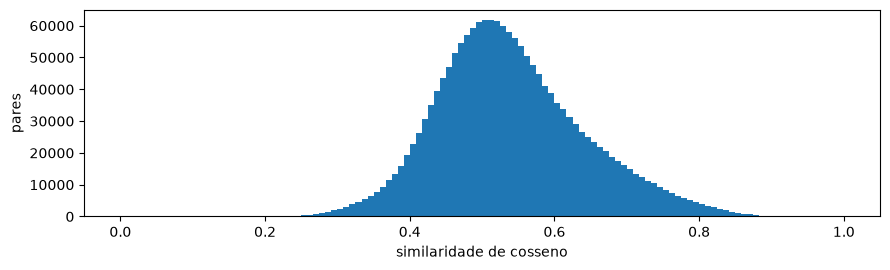

1,701,090 pares


In [6]:
# Pega só o triângulo superior da matriz, que tem cada par uma vez e ignora a diagonal
upper = np.triu_indices(len(image_names), 1)
sim_values = similarities[upper]

fig, ax = plt.subplots(figsize=(9, 2.8))
ax.hist(sim_values, bins=120, range=(0, 1))
ax.set_xlabel("similaridade de cosseno")
ax.set_ylabel("pares")
fig.tight_layout()
plt.show()

print(f"{len(sim_values):,} pares")

Duas fotos sem relação nenhuma dão cerca de **0,53**, e não zero. 

## Quase-duplicatas semânticas

Se duas imagens muito parecidas são candidatas a duplicata, basta percorrer cada linha de
`order` e pegar os vizinhos que passam de um limiar.

In [7]:
def find_semantic_duplicates(order, similarities, threshold=0.95):
    """Para cada imagem, quais outras estão acima do limiar de similaridade."""
    duplicates = {}
    for index, neighbours in enumerate(order):
        # Descartamos a própria imagem comparando o índice. Descartar a coluna 0 não
        # funciona: quando existe uma cópia exata, as duas empatam em 1.0 e a ordem
        # entre elas é arbitrária.
        close = []
        for other in neighbours:
            if other != index and similarities[index, other] >= threshold:
                close.append(other)
        if close:
            duplicates[index] = close
    return duplicates


duplicates = find_semantic_duplicates(order, similarities, threshold=0.95)

print(f"{len(duplicates)} imagens com alguma parecida")

231 imagens com alguma parecida


Na aula passada, o pHash com limiar de 10 bits encontrou 139 pares. Agora são bem mais, e
entre eles estão os espelhamentos e as rotações que o hash tinha deixado passar.

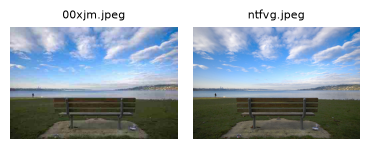

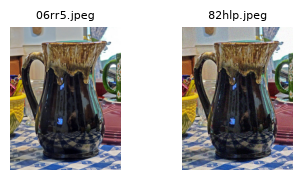

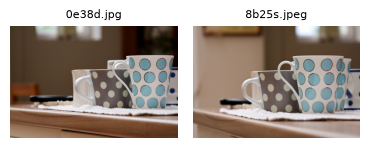

In [8]:
def show_similar(duplicates, image_names, n=3):
    """Mostra imagens similares."""
    show = list(duplicates.items())[:n]

    for ref_idx, nei_idxs in show:
        ref_name = image_names[ref_idx]
        nei_names = [image_names[i] for i in nei_idxs]
        
        names = [ref_name] + nei_names
        show_grid(names, columns=len(names))

show_similar(duplicates, image_names, n=3)

## Imagens fora do padrão

A mesma matriz responde a pergunta oposta: quais imagens **não têm ninguém perto**?

O escore de cada imagem é o raio que preciso abrir em volta dela para encontrar `k` parecidas.
Quem está numa região cheia tem raio pequeno, quem está sozinho tem raio grande.

In [9]:
def outlier_scores(order, similarities, k=20):
    """Distância até o k-ésimo vizinho mais próximo de cada imagem."""

    # Índice do k-ésimo vizinho mais próximo de cada imagem. A coluna 0 é a própria imagem, 
    # então o k-ésimo vizinho está na coluna k
    viz_idx = order[:, k]
    # Similaridade do k-ésimo vizinho mais próximo 
    rows = np.arange(len(order))
    sim_viz = similarities[rows, viz_idx]

    return 1 - sim_viz


scores = pd.Series(outlier_scores(order, similarities, k=20), index=image_names)

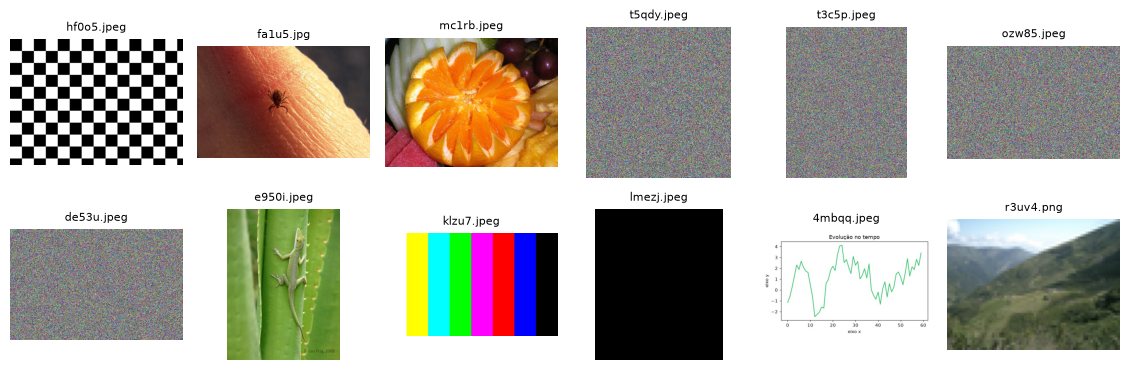

In [10]:
top_outliers = list(scores.nlargest(12).index)
show_grid(top_outliers)

Aparecem imagens que não são fotografia nenhuma: ruído, padrões de teste, capturas de tela.
Mas aparecem também fotos legítimas da classe `other`, que é heterogênea por definição.

**Fora do padrão não quer dizer ruim.** O escore responde "esta imagem é diferente das outras
deste conjunto", e não "esta imagem está com defeito".

## Agrupar sem rótulo

O `k-means` divide o conjunto em grupos usando só os vetores, sem olhar nenhum rótulo.

In [11]:
from sklearn.cluster import KMeans

labels = pd.read_csv(dataset_dir / "labels_consensus.csv").set_index("image_name")

# n_init e random_state fixos, senão o número de cada cluster muda a cada execução
kmeans = KMeans(n_clusters=9, n_init=10, random_state=0).fit(features)
clusters = pd.Series(kmeans.labels_, index=image_names)

table = pd.crosstab(labels.loc[image_names, "class_name"], clusters)
table

col_0,0,1,2,3,4,5,6,7,8
class_name,,,,,,,,,
coffee mug,140,6,0,17,0,3,4,2,51
cup,103,5,3,41,0,1,2,2,33
dining table,5,2,4,3,0,274,9,2,13
folding chair,2,1,5,1,0,23,28,0,9
other,17,125,9,11,8,9,21,4,49
park bench,3,9,117,2,0,7,171,3,7
pitcher,22,6,1,137,0,3,2,2,23
sports car,1,0,0,2,53,6,1,4,0
water jug,22,8,3,72,1,1,5,1,103


Se os clusters batessem com as classes, o agrupamento não teria dito nada que já não
soubéssemos. O que interessa são as **discordâncias**.

Repare na coluna com poucas imagens espalhadas por quase todas as classes. Uma coluna assim é
o sinal mais claro que o agrupamento dá.

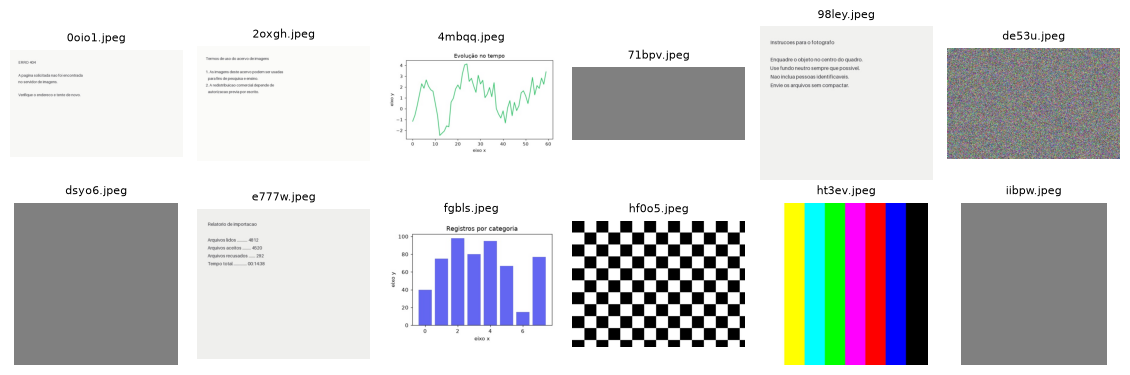

In [12]:
def show_cluster(clusters, cluster_id, count=12):
    """Mostra algumas imagens de um cluster, com a classe de cada uma."""
    members = list(clusters[clusters == cluster_id].index)[:count]
    show_grid(members)

members = show_cluster(clusters, cluster_id=7)

## Mapas em duas dimensões

Não dá para visualizar os dados em 384 dimensões. O `PCA` escolhe as direções de maior variância dos dados, e o `UMAP`
tenta preservar a vizinhança de cada ponto.

### PCA

In [13]:
from sklearn.decomposition import PCA


pca = PCA(random_state=0)
pca_features = pca.fit_transform(features)
# O resultado do PCA possui as mesmas dimensões que os dados de entrada
print(pca_features.shape)

(1845, 384)


In [14]:
# explained_variance_ possui a variância dos dados ao longo de cada eixo do PCA
pca_variance = pca.explained_variance_
print(pca_variance[:10])

[0.05570763 0.03050032 0.01724402 0.01507255 0.01172096 0.01013581
 0.00903456 0.00881814 0.00778852 0.00759864]


In [15]:
variance = features.var(axis=0)
print(f"Variância total dos dados: {variance.sum()}")
print(f"Variância total do PCA: {pca_variance.sum()}")

Variância total dos dados: 0.4600445032119751
Variância total do PCA: 0.4602940082550049


Podemos definir quanto de variância queremos preservar nos dados:

Text(0.5, 1.0, 'Variância Explicada pelo PCA')

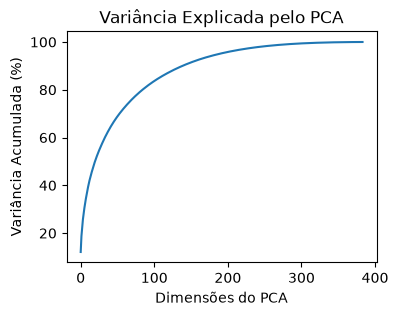

In [16]:
# Porcentagem de variância mantida por n eixos do PCA
variance_percentage = 100*pca_variance/pca_variance.sum()
cumulative_var = np.cumsum(variance_percentage)

fig, ax = plt.subplots()
ax.plot(cumulative_var)
ax.set_xlabel("Dimensões do PCA")
ax.set_ylabel("Variância Acumulada (%)")
ax.set_title("Variância Explicada pelo PCA")

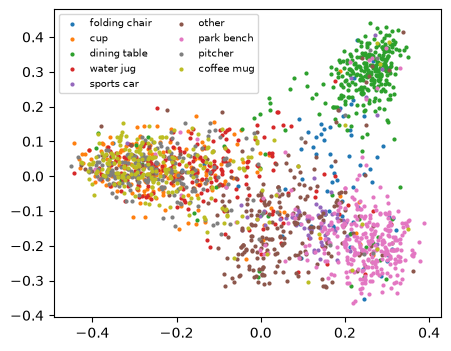

In [17]:
def plot_projection(points, class_names):
    """Desenha um mapa 2D colorindo cada ponto de acordo com sua classe."""
    colors = plt.get_cmap("tab10")
    classes = set(class_names)

    fig, ax = plt.subplots(figsize=(5, 4))
    for index, value in enumerate(classes):
        mask = class_names == value
        ax.scatter(points[mask, 0], points[mask, 1], s=4, color=colors(index), label=value)
    ax.legend(fontsize=7, ncols=2)

projection = pca_features[:, :2]
class_names = labels.loc[image_names, "class_name"]

plot_projection(projection, class_names)

In [18]:
# Variância explicada pelas duas primeiras dimensões do PCA
print(f"Variância explicada pelos pontos do gráfico: {cumulative_var[1]:.2f}%")

Variância explicada pelos pontos do gráfico: 18.73%


### UMAP

O UMAP foi desenvolvido para análise visual exploratória. Não é possível analisar a quantidade de informação preservada, mas ele preserva aproximadamente a vizinhança de cada ponto, o que é útil para encontrar grupos e outliers.

/home/chcomin/miniconda3/envs/pvd/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


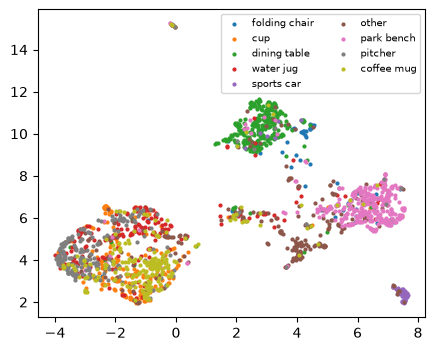

In [19]:
import umap

projection = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine", random_state=0).fit_transform(features)
plot_projection(projection, class_names)

O UMAP serve para levantar hipóteses sobre a estrutura dos dados, mas não para obter conclusões. 